In [1]:

from pathlib import Path
import sys
import os

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import plotly.graph_objects as go
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import random
from torch.amp import autocast, GradScaler

from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names
from utils.ImbalancedSampling import MixupAugmentation, TemporalAugmentation
from models.lstmv2 import LSTMModel
from utils.LDS_FocalR_Loss import EnhancedLDS_FocalR_Loss
from utils.FDS_RankSim import FDS_RankSim_Wrapper



Project root: e:\Automation_IT\3\Drift case study\MAIT_G2_Drift_Challenge


In [2]:
# ============================================================================
# CELL 2: CENTRAL CONFIGURATION
# ============================================================================

CONFIG = {
    # PATHS
    'TRAIN_PATH': "../datasets_challenge/train",
    'TEST_PATH': "../datasets_challenge/test",
    'DIST_CSV': "../datasets_challenge/sideSlip_distribution.csv",
    'CHECKPOINT_NAME': "best_bilstm_optimal.pth",
    'SUBMISSION_CSV': "predictions.csv",
    
    # REPRODUCIBILITY
    'SEED': 42,
    
    # DATA LOADING
    'TRAIN_RATIO': 0.8,
    'BATCH_SIZE': 256,
    'SEQUENCE_LENGTH': 20,
    'THRESHOLD': True,
    'THRESHOLD_VALUE': 3.0,
    'THRESHOLD_COLUMN': "vxCG",
    'COLUMNS_TO_DROP': ["sideSlip", "vyCG", "time", "longitude", "latitude"],
    'TARGET': "sideSlip",
    'SCALING': True,
    
    # MODEL ARCHITECTURE
    'MODEL_TYPE': 'BiLSTM_Attention',
    'RNN_UNITS': 128,
    'FC_UNITS': 128,
    'NUM_LAYERS': 2,
    'DROPOUT': 0.3,
    'BIDIRECTIONAL': True,
    'USE_ATTENTION': True,
    'FEATURE_DIM': 128,
    
    # LOSS FUNCTION (LDS + Focal-R)
    'BUCKET_WEIGHTS': (1.0, 3.5, 8.0),
    'LDS_KERNEL': 'gaussian',
    'LDS_KS': 7,
    'LDS_SIGMA': 2.5,
    'FOCAL_GAMMA': 1.2,
    'USE_HUBER': True,
    'HUBER_BETA': 0.08,
    'NUM_BINS': 100,
    
    # FDS + RANKSIM
    'USE_FDS': True,
    'FDS_FEATURE_DIM': 128,
    'RANKSIM_WEIGHT': 0.03,
    
    # AUGMENTATION
    'MIXUP_ALPHA': 0.2,
    'MIXUP_PROB': 0.4,
    'MIXUP_PRIORITIZE_RARE': True,
    'MIXUP_RARE_THRESHOLD': 5.85,
    'TEMPORAL_NOISE_PROB': 0.5,
    'TEMPORAL_NOISE_STD': 0.02,
    'TEMPORAL_MASK_PROB': 0.2,
    'TEMPORAL_MASK_RATIO': 0.15,
    'TEMPORAL_SCALE_PROB': 0.25,
    'TEMPORAL_SCALE_RANGE': (0.93, 1.07),
    'AUGMENTATION_EPOCHS': 120,
    
    # OPTIMIZER
    'LEARNING_RATE': 5e-4,
    'WEIGHT_DECAY': 1e-3,
    'BETAS': (0.9, 0.999),
    
    # SCHEDULER
    'SCHEDULER_T_MAX': 400,
    'SCHEDULER_ETA_MIN': 1e-6,
    
    # TRAINING
    'NUM_EPOCHS': 400,
    'EARLY_STOP_PATIENCE': 400,
    'GRADIENT_CLIP': 1.0,
    'USE_AMP': True,
    
    # TEST-TIME AUGMENTATION
    'TTA_N_AUGMENTATIONS': 9,
    'TTA_NOISE_LEVELS': [0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.035, 0.04],
    'TTA_ORIGINAL_WEIGHT': 2.5,
    
    # VISUALIZATION
    'FIG_SIZE': (14, 8),
    'PLOTLY_WIDTH': 1200,
    'PLOTLY_HEIGHT': 500,
}


In [3]:
# ============================================================================
# CELL 3: SET RANDOM SEED
# ============================================================================

seed_everything(CONFIG['SEED'])
print(f"✓ Random seed set to {CONFIG['SEED']}")

✓ Random seed set to 42


In [4]:
# ============================================================================
# CELL 4: LOAD TRAINING DATA
# ============================================================================

print(f"\nLoading training data from: {CONFIG['TRAIN_PATH']}")
print(f"Batch size: {CONFIG['BATCH_SIZE']} | Sequence length: {CONFIG['SEQUENCE_LENGTH']}")

train_dataloader, val_dataloader, pipeline = load_data(
    train_path=CONFIG['TRAIN_PATH'],
    train_ratio=CONFIG['TRAIN_RATIO'],
    batchsize=CONFIG['BATCH_SIZE'],
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold=CONFIG['THRESHOLD'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    scaling=CONFIG['SCALING'],
    seed=CONFIG['SEED'],
    verbose=True
)

print(f"✓ Training batches: {len(train_dataloader)}")
print(f"✓ Validation batches: {len(val_dataloader)}")


Loading training data from: ../datasets_challenge/train
Batch size: 256 | Sequence length: 20
train_part_001.csv: Train=9473, Val=2368, Block=[3392:5760]
train_part_003.csv: Train=7895, Val=1973, Block=[7115:9088]
train_part_004.csv: Train=1145, Val=285, Block=[837:1122]
train_part_005.csv: Train=1221, Val=304, Block=[1159:1463]
train_part_006.csv: Train=16405, Val=4101, Block=[15872:19973]
train_part_007.csv: Train=1228, Val=306, Block=[426:732]
train_part_008.csv: Train=17777, Val=4443, Block=[14000:18443]
train_part_009.csv: Train=6176, Val=1543, Block=[2105:3648]
train_part_010.csv: Train=7567, Val=1891, Block=[7157:9048]
train_part_011.csv: Train=12416, Val=3103, Block=[7705:10808]
train_part_012.csv: Train=897, Val=224, Block=[111:335]
train_part_013.csv: Train=7866, Val=1966, Block=[4557:6523]
train_part_015.csv: Train=6678, Val=1669, Block=[3023:4692]
train_part_017.csv: Train=449, Val=112, Block=[177:289]
train_part_018.csv: Train=3860, Val=964, Block=[2253:3217]
train_part_0


DATA IMBALANCE ANALYSIS

📊 BASIC STATISTICS:
   Total samples: 109,599
   Mean: 0.0306°
   Std: 1.4638°
   Range: [-14.2100°, 11.6500°]
   Median: -0.0300°

📈 SHOT BAND DISTRIBUTION:
   Many    :  99,538 (90.82%)
   Medium  :   7,613 ( 6.95%)
   Few     :   2,448 ( 2.23%)

⚠️  IMBALANCE METRICS:
   Many/Few ratio: 40.7x
   Few-shot percentage: 2.23%

📐 PERCENTILE ANALYSIS:
   50th (Median): 0.4500°
   90th: 2.2400° ← Many/Medium threshold
   99th: 5.8500° ← Medium/Few threshold

✓ Updated MIXUP_RARE_THRESHOLD to 5.8500°


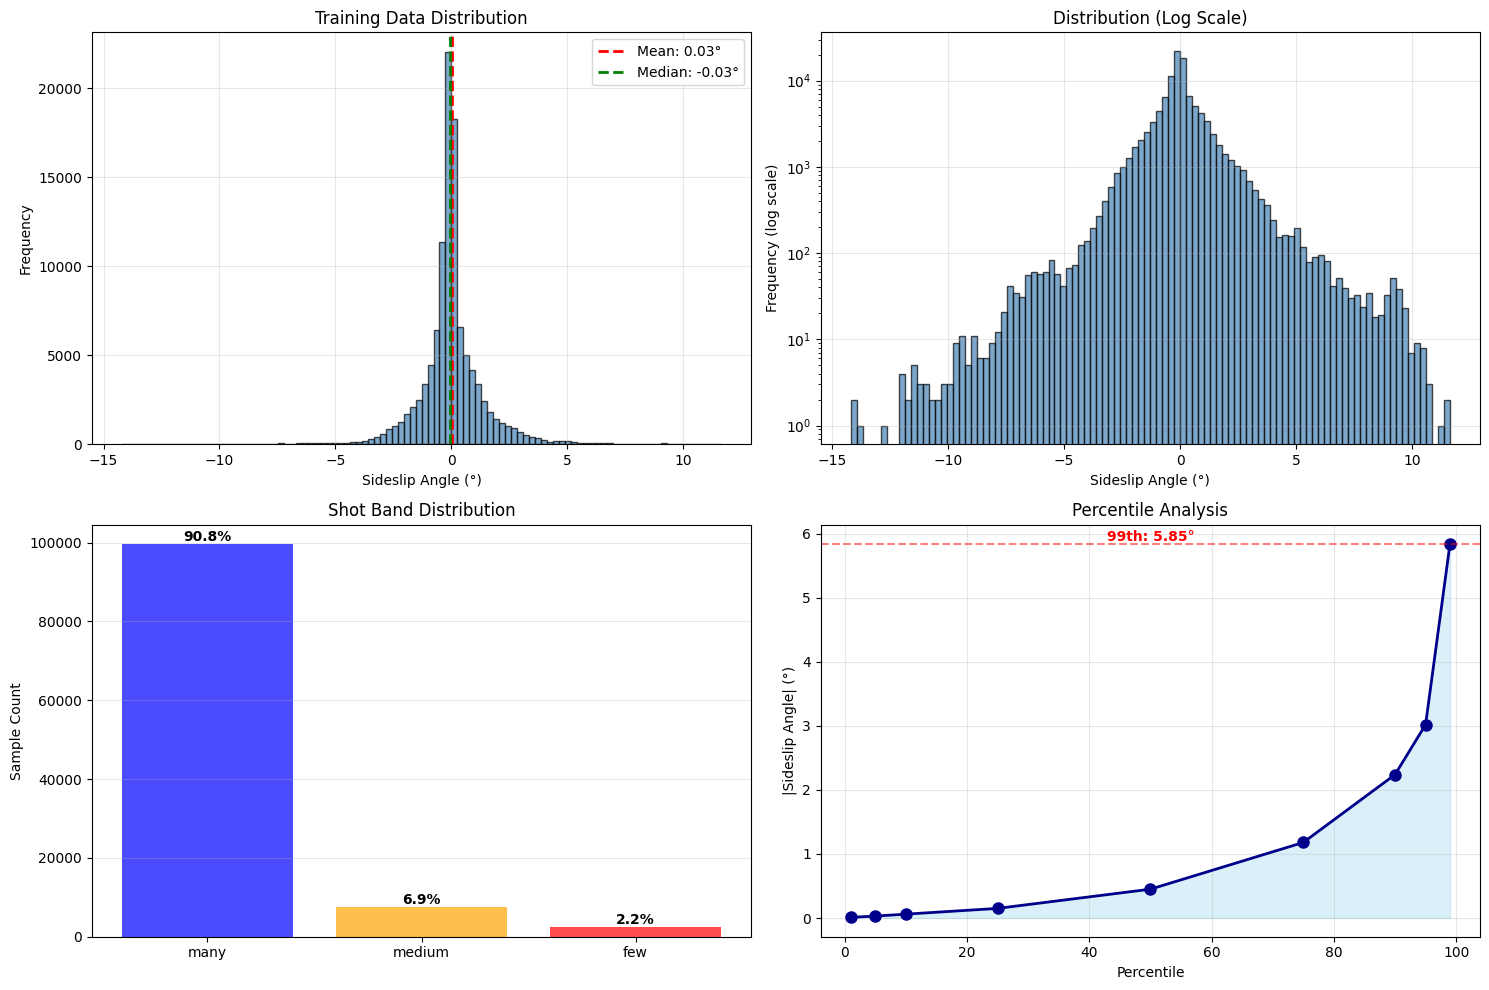


✓ Imbalance analysis complete


In [5]:
# ============================================================================
# CELL 5: DATA IMBALANCE ANALYSIS
# ============================================================================

print("\n" + "="*80)
print("DATA IMBALANCE ANALYSIS")
print("="*80)

# Extract training targets
all_train_targets = []
for i in range(len(train_dataloader.dataset)):
    _, y = train_dataloader.dataset[i]
    all_train_targets.append(y.item())

y_train_np = np.array(all_train_targets)

# Basic statistics
print(f"\n📊 BASIC STATISTICS:")
print(f"   Total samples: {len(y_train_np):,}")
print(f"   Mean: {y_train_np.mean():.4f}°")
print(f"   Std: {y_train_np.std():.4f}°")
print(f"   Range: [{y_train_np.min():.4f}°, {y_train_np.max():.4f}°]")
print(f"   Median: {np.median(y_train_np):.4f}°")

# Load shot band mapping
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
shot_band_mapping = dist_df.groupby("sideSlip")["band"].first()

# Map to bands
y_train_rounded = np.round(y_train_np, 1)
bands = pd.Series(y_train_rounded).map(shot_band_mapping).fillna("unknown")
band_counts = bands.value_counts()

# Shot band distribution
print(f"\n📈 SHOT BAND DISTRIBUTION:")
for band in ['many', 'medium', 'few', 'unknown']:
    if band in band_counts.index:
        count = band_counts[band]
        pct = count / len(y_train_np) * 100
        print(f"   {band.capitalize():8s}: {count:7,} ({pct:5.2f}%)")

# Imbalance ratio
many_count = band_counts.get('many', 0)
few_count = band_counts.get('few', 1)
imbalance_ratio = many_count / few_count if few_count > 0 else float('inf')
print(f"\n⚠️  IMBALANCE METRICS:")
print(f"   Many/Few ratio: {imbalance_ratio:.1f}x")
print(f"   Few-shot percentage: {(few_count/len(y_train_np)*100):.2f}%")

# Calculate percentiles
abs_y = np.abs(y_train_np)
percentiles = [1, 5, 10, 25, 50, 75, 90, 95, 99]
percentile_values = np.percentile(abs_y, percentiles)

print(f"\n📐 PERCENTILE ANALYSIS:")
print(f"   50th (Median): {percentile_values[4]:.4f}°")
print(f"   90th: {percentile_values[6]:.4f}° ← Many/Medium threshold")
print(f"   99th: {percentile_values[8]:.4f}° ← Medium/Few threshold")

# Update CONFIG with data-driven threshold
CONFIG['MIXUP_RARE_THRESHOLD'] = float(percentile_values[8])
print(f"\n✓ Updated MIXUP_RARE_THRESHOLD to {CONFIG['MIXUP_RARE_THRESHOLD']:.4f}°")

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Distribution histogram
axes[0, 0].hist(y_train_np, bins=100, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(y_train_np.mean(), color='red', linestyle='--', linewidth=2, 
                   label=f'Mean: {y_train_np.mean():.2f}°')
axes[0, 0].axvline(np.median(y_train_np), color='green', linestyle='--', linewidth=2, 
                   label=f'Median: {np.median(y_train_np):.2f}°')
axes[0, 0].set_xlabel('Sideslip Angle (°)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Training Data Distribution')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Log-scale histogram
axes[0, 1].hist(y_train_np, bins=100, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 1].set_yscale('log')
axes[0, 1].set_xlabel('Sideslip Angle (°)')
axes[0, 1].set_ylabel('Frequency (log scale)')
axes[0, 1].set_title('Distribution (Log Scale)')
axes[0, 1].grid(alpha=0.3)

# Shot band bar chart
band_colors = {'many': 'blue', 'medium': 'orange', 'few': 'red', 'unknown': 'gray'}
colors = [band_colors.get(b, 'gray') for b in band_counts.index]
axes[1, 0].bar(range(len(band_counts)), band_counts.values, color=colors, alpha=0.7)
axes[1, 0].set_xticks(range(len(band_counts)))
axes[1, 0].set_xticklabels(band_counts.index)
axes[1, 0].set_ylabel('Sample Count')
axes[1, 0].set_title('Shot Band Distribution')
axes[1, 0].grid(alpha=0.3, axis='y')
for i, (count, pct) in enumerate(zip(band_counts.values, band_counts.values / len(y_train_np) * 100)):
    axes[1, 0].text(i, count, f'{pct:.1f}%', ha='center', va='bottom', fontweight='bold')

# Percentile curve
axes[1, 1].plot(percentiles, percentile_values, marker='o', markersize=8, linewidth=2, color='darkblue')
axes[1, 1].fill_between(percentiles, 0, percentile_values, alpha=0.3, color='skyblue')
axes[1, 1].axhline(percentile_values[-1], color='red', linestyle='--', alpha=0.5)
axes[1, 1].text(50, percentile_values[-1], f'99th: {percentile_values[-1]:.2f}°', 
                ha='center', va='bottom', color='red', fontweight='bold')
axes[1, 1].set_xlabel('Percentile')
axes[1, 1].set_ylabel('|Sideslip Angle| (°)')
axes[1, 1].set_title('Percentile Analysis')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("✓ Imbalance analysis complete")
print("="*80)

In [6]:
# ============================================================================
# CELL 6: MODEL CONFIGURATION
# ============================================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n{'='*80}")
print(f"DEVICE: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
print(f"{'='*80}\n")

# Mixed precision scaler
scaler = GradScaler(device=device.type) if CONFIG['USE_AMP'] else None

# Get input size
X_sample, _ = next(iter(train_dataloader))
input_size = X_sample.shape[2]
print(f"Input shape: {X_sample.shape} → Features: {input_size}")

# ============================================================================
# CREATE MODEL: BiLSTM with Attention
# ============================================================================
base_model = LSTMModel(
    input_size=input_size,
    output_size=1,
    rnn_units=CONFIG['RNN_UNITS'],
    fc_units=CONFIG['FC_UNITS'],
    dropout=CONFIG['DROPOUT'],
    num_layers=CONFIG['NUM_LAYERS'],
    use_batch_norm=True,
    bidirectional=CONFIG['BIDIRECTIONAL'],
    feature_dim=CONFIG['FEATURE_DIM']
).to(device)

# ============================================================================
# CREATE LOSS: Enhanced LDS + Focal-R
# ============================================================================
criterion = EnhancedLDS_FocalR_Loss(
    train_targets=y_train_np,
    bucket_weights=CONFIG['BUCKET_WEIGHTS'],
    lds_kernel=CONFIG['LDS_KERNEL'],
    lds_ks=CONFIG['LDS_KS'],
    lds_sigma=CONFIG['LDS_SIGMA'],
    focal_gamma=CONFIG['FOCAL_GAMMA'],
    use_huber=CONFIG['USE_HUBER'],
    huber_beta=CONFIG['HUBER_BETA'],
    num_bins=CONFIG['NUM_BINS']
).to(device)

# ============================================================================
# WRAP WITH FDS + RANKSIM
# ============================================================================
if CONFIG['USE_FDS']:
    wrapped_model = FDS_RankSim_Wrapper(
        model=base_model,
        main_criterion=criterion,
        fds_feature_dim=CONFIG['FDS_FEATURE_DIM'],
        ranksim_weight=CONFIG['RANKSIM_WEIGHT']
    ).to(device)
    print("✓ Model wrapped with FDS + RankSim")
else:
    wrapped_model = base_model
    print("✓ Using base model (no FDS wrapper)")

# Model statistics
total_params = sum(p.numel() for p in base_model.parameters())
trainable_params = sum(p.numel() for p in base_model.parameters() if p.requires_grad)
print(f"\n📊 MODEL STATISTICS:")
print(f"   Type: {CONFIG['MODEL_TYPE']}")
print(f"   Parameters: {total_params:,} ({trainable_params:,} trainable)")
print(f"   Size: {total_params * 4 / 1024**2:.2f} MB")
print(f"   Hidden units: {CONFIG['RNN_UNITS']}")
print(f"   Layers: {CONFIG['NUM_LAYERS']}")
print(f"   Bidirectional: {CONFIG['BIDIRECTIONAL']}")
print(f"   Attention: {CONFIG['USE_ATTENTION']}\n")


DEVICE: cpu

Input shape: torch.Size([256, 20, 22]) → Features: 22

[EnhancedLDS+FocalR Loss Configuration]
Bucket thresholds: Many≤2.2400° | Medium≤5.8500°
Data distribution:
  Many:    98716 (90.07%)
  Medium:   9789 ( 8.93%)
  Few:      1094 ( 1.00%)
Bucket weights: 1.0 / 3.5 / 8.0
Focal gamma: 1.2 | Huber beta: 0.08
LDS: kernel=gaussian, sigma=2.5

✓ Model wrapped with FDS + RankSim

📊 MODEL STATISTICS:
   Type: BiLSTM_Attention
   Parameters: 675,885 (675,885 trainable)
   Size: 2.58 MB
   Hidden units: 128
   Layers: 2
   Bidirectional: True
   Attention: True



In [7]:
# ============================================================================
# CELL 7: TRAINING SETUP
# ============================================================================

# Augmentation
mixup = MixupAugmentation(
    alpha=CONFIG['MIXUP_ALPHA'],
    prob=CONFIG['MIXUP_PROB'],
    prioritize_rare=CONFIG['MIXUP_PRIORITIZE_RARE'],
    rare_threshold=CONFIG['MIXUP_RARE_THRESHOLD']
)

temporal_aug = TemporalAugmentation(
    noise_prob=CONFIG['TEMPORAL_NOISE_PROB'],
    noise_std=CONFIG['TEMPORAL_NOISE_STD'],
    mask_prob=CONFIG['TEMPORAL_MASK_PROB'],
    mask_ratio=CONFIG['TEMPORAL_MASK_RATIO'],
    scale_prob=CONFIG['TEMPORAL_SCALE_PROB'],
    scale_range=CONFIG['TEMPORAL_SCALE_RANGE']
)

print("✓ Augmentation configured:")
print(f"  - Mixup: α={CONFIG['MIXUP_ALPHA']}, prob={CONFIG['MIXUP_PROB']}")
print(f"  - Temporal: noise={CONFIG['TEMPORAL_NOISE_STD']}, mask={CONFIG['TEMPORAL_MASK_RATIO']}")

# Optimizer
optimizer = torch.optim.AdamW(
    wrapped_model.parameters(),
    lr=CONFIG['LEARNING_RATE'],
    weight_decay=CONFIG['WEIGHT_DECAY'],
    betas=CONFIG['BETAS']
)

# Scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CONFIG['SCHEDULER_T_MAX'],
    eta_min=CONFIG['SCHEDULER_ETA_MIN']
)

print(f"✓ Optimizer: AdamW (lr={CONFIG['LEARNING_RATE']}, wd={CONFIG['WEIGHT_DECAY']})")
print(f"✓ Scheduler: CosineAnnealing (T_max={CONFIG['SCHEDULER_T_MAX']})")

# Training state
train_curve, val_curve = [], []
train_mae_curve, val_mae_curve = [], []
bucket_many, bucket_medium, bucket_few = [], [], []
learning_rate_curve = []

best_loss = np.inf
best_epoch = -1

print(f"\n{'='*80}")
print(f"READY TO TRAIN")
print(f"{'='*80}\n")

✓ Augmentation configured:
  - Mixup: α=0.2, prob=0.4
  - Temporal: noise=0.02, mask=0.15
✓ Optimizer: AdamW (lr=0.0005, wd=0.001)
✓ Scheduler: CosineAnnealing (T_max=400)

READY TO TRAIN



In [8]:
# ============================================================================
# CELL 6: MODEL CONFIGURATION
# ============================================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n{'='*80}")
print(f"DEVICE: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
print(f"{'='*80}\n")

# Mixed precision scaler
scaler = GradScaler(device=device.type) if CONFIG['USE_AMP'] else None

# Get input size
X_sample, _ = next(iter(train_dataloader))
input_size = X_sample.shape[2]
print(f"Input shape: {X_sample.shape} → Features: {input_size}")

# ============================================================================
# CREATE MODEL: BiLSTM with Attention
# ============================================================================
base_model = LSTMModel(
    input_size=input_size,
    output_size=1,
    rnn_units=CONFIG['RNN_UNITS'],
    fc_units=CONFIG['FC_UNITS'],
    dropout=CONFIG['DROPOUT'],
    num_layers=CONFIG['NUM_LAYERS'],
    use_batch_norm=True,
    bidirectional=CONFIG['BIDIRECTIONAL'],
    feature_dim=CONFIG['FEATURE_DIM']
).to(device)

# ============================================================================
# CREATE LOSS: Enhanced LDS + Focal-R
# ============================================================================
criterion = EnhancedLDS_FocalR_Loss(
    train_targets=y_train_np,
    bucket_weights=CONFIG['BUCKET_WEIGHTS'],
    lds_kernel=CONFIG['LDS_KERNEL'],
    lds_ks=CONFIG['LDS_KS'],
    lds_sigma=CONFIG['LDS_SIGMA'],
    focal_gamma=CONFIG['FOCAL_GAMMA'],
    use_huber=CONFIG['USE_HUBER'],
    huber_beta=CONFIG['HUBER_BETA'],
    num_bins=CONFIG['NUM_BINS']
).to(device)

# ============================================================================
# WRAP WITH FDS + RANKSIM
# ============================================================================
if CONFIG['USE_FDS']:
    wrapped_model = FDS_RankSim_Wrapper(
        model=base_model,
        main_criterion=criterion,
        fds_feature_dim=CONFIG['FDS_FEATURE_DIM'],
        ranksim_weight=CONFIG['RANKSIM_WEIGHT']
    ).to(device)
    print("✓ Model wrapped with FDS + RankSim")
else:
    wrapped_model = base_model
    print("✓ Using base model (no FDS wrapper)")

# Model statistics
total_params = sum(p.numel() for p in base_model.parameters())
trainable_params = sum(p.numel() for p in base_model.parameters() if p.requires_grad)
print(f"\n📊 MODEL STATISTICS:")
print(f"   Type: {CONFIG['MODEL_TYPE']}")
print(f"   Parameters: {total_params:,} ({trainable_params:,} trainable)")
print(f"   Size: {total_params * 4 / 1024**2:.2f} MB")
print(f"   Hidden units: {CONFIG['RNN_UNITS']}")
print(f"   Layers: {CONFIG['NUM_LAYERS']}")
print(f"   Bidirectional: {CONFIG['BIDIRECTIONAL']}")
print(f"   Attention: {CONFIG['USE_ATTENTION']}\n")


DEVICE: cpu

Input shape: torch.Size([256, 20, 22]) → Features: 22

[EnhancedLDS+FocalR Loss Configuration]
Bucket thresholds: Many≤2.2400° | Medium≤5.8500°
Data distribution:
  Many:    98716 (90.07%)
  Medium:   9789 ( 8.93%)
  Few:      1094 ( 1.00%)
Bucket weights: 1.0 / 3.5 / 8.0
Focal gamma: 1.2 | Huber beta: 0.08
LDS: kernel=gaussian, sigma=2.5

✓ Model wrapped with FDS + RankSim

📊 MODEL STATISTICS:
   Type: BiLSTM_Attention
   Parameters: 675,885 (675,885 trainable)
   Size: 2.58 MB
   Hidden units: 128
   Layers: 2
   Bidirectional: True
   Attention: True



In [9]:
# ============================================================================
# CELL 7: TRAINING SETUP
# ============================================================================

# Augmentation
mixup = MixupAugmentation(
    alpha=CONFIG['MIXUP_ALPHA'],
    prob=CONFIG['MIXUP_PROB'],
    prioritize_rare=CONFIG['MIXUP_PRIORITIZE_RARE'],
    rare_threshold=CONFIG['MIXUP_RARE_THRESHOLD']
)

temporal_aug = TemporalAugmentation(
    noise_prob=CONFIG['TEMPORAL_NOISE_PROB'],
    noise_std=CONFIG['TEMPORAL_NOISE_STD'],
    mask_prob=CONFIG['TEMPORAL_MASK_PROB'],
    mask_ratio=CONFIG['TEMPORAL_MASK_RATIO'],
    scale_prob=CONFIG['TEMPORAL_SCALE_PROB'],
    scale_range=CONFIG['TEMPORAL_SCALE_RANGE']
)

print("✓ Augmentation configured:")
print(f"  - Mixup: α={CONFIG['MIXUP_ALPHA']}, prob={CONFIG['MIXUP_PROB']}")
print(f"  - Temporal: noise={CONFIG['TEMPORAL_NOISE_STD']}, mask={CONFIG['TEMPORAL_MASK_RATIO']}")

# Optimizer
optimizer = torch.optim.AdamW(
    wrapped_model.parameters(),
    lr=CONFIG['LEARNING_RATE'],
    weight_decay=CONFIG['WEIGHT_DECAY'],
    betas=CONFIG['BETAS']
)

# Scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CONFIG['SCHEDULER_T_MAX'],
    eta_min=CONFIG['SCHEDULER_ETA_MIN']
)

print(f"✓ Optimizer: AdamW (lr={CONFIG['LEARNING_RATE']}, wd={CONFIG['WEIGHT_DECAY']})")
print(f"✓ Scheduler: CosineAnnealing (T_max={CONFIG['SCHEDULER_T_MAX']})")

# Training state
train_curve, val_curve = [], []
train_mae_curve, val_mae_curve = [], []
bucket_many, bucket_medium, bucket_few = [], [], []
bucket_loss_many_curve, bucket_loss_medium_curve, bucket_loss_few_curve = [], [], []  # NEW!
learning_rate_curve = []

best_loss = np.inf
best_epoch = -1

print(f"\n{'='*80}")
print(f"READY TO TRAIN")
print(f"{'='*80}\n")

✓ Augmentation configured:
  - Mixup: α=0.2, prob=0.4
  - Temporal: noise=0.02, mask=0.15
✓ Optimizer: AdamW (lr=0.0005, wd=0.001)
✓ Scheduler: CosineAnnealing (T_max=400)

READY TO TRAIN



In [10]:
# ============================================================================
# CELL 8: TRAINING LOOP
# ============================================================================

for epoch in range(CONFIG['NUM_EPOCHS']):
    # =============== TRAINING ===============
    wrapped_model.train()
    if hasattr(wrapped_model, 'set_epoch'):
        wrapped_model.set_epoch(epoch)
    
    running_loss, running_mae = 0.0, 0.0

    for step, (xb, yb) in enumerate(train_dataloader):
        xb, yb = xb.to(device), yb.to(device).reshape(-1, 1)
        
        if epoch < CONFIG['AUGMENTATION_EPOCHS']:
            xb = temporal_aug(xb)
        xb, yb = mixup(xb, yb)

        optimizer.zero_grad(set_to_none=True)
        
        if CONFIG['USE_AMP'] and device.type == "cuda":
            with autocast(device_type='cuda'):
                if CONFIG['USE_FDS']:
                    total_loss, pred, _, _ = wrapped_model(xb, yb, update_stats=True)
                else:
                    pred = wrapped_model(xb)
                    total_loss = criterion(pred, yb)
        else:
            if CONFIG['USE_FDS']:
                total_loss, pred, _, _ = wrapped_model(xb, yb, update_stats=True)
            else:
                pred = wrapped_model(xb)
                total_loss = criterion(pred, yb)
        
        if scaler is not None:
            scaler.scale(total_loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(wrapped_model.parameters(), CONFIG['GRADIENT_CLIP'])
            scaler.step(optimizer)
            scaler.update()
        else:
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(wrapped_model.parameters(), CONFIG['GRADIENT_CLIP'])
            optimizer.step()

        running_loss += total_loss.item()
        running_mae += (pred - yb).abs().mean().item()

    avg_train_loss = running_loss / len(train_dataloader)
    avg_train_mae = running_mae / len(train_dataloader)
    train_curve.append(avg_train_loss)
    train_mae_curve.append(avg_train_mae)

    # =============== VALIDATION ===============
    wrapped_model.eval()
    running_val_loss, running_val_mae = 0.0, 0.0
    all_val_preds, all_val_targets = [], []

    with torch.no_grad():
        for xv, yv in val_dataloader:
            xv, yv = xv.to(device), yv.to(device).reshape(-1, 1)
            
            if CONFIG['USE_FDS']:
                total_loss_val, pred_val, _, _ = wrapped_model(xv, yv, update_stats=False)
            else:
                pred_val = wrapped_model(xv)
                total_loss_val = criterion(pred_val, yv)
            
            running_val_loss += total_loss_val.item()
            running_val_mae += (pred_val - yv).abs().mean().item()
            all_val_preds.append(pred_val)
            all_val_targets.append(yv)

    all_val_preds = torch.cat(all_val_preds, dim=0)
    all_val_targets = torch.cat(all_val_targets, dim=0)
    bucket_stats = criterion.bucket_metrics(all_val_preds, all_val_targets)

    avg_val_loss = running_val_loss / len(val_dataloader)
    avg_val_mae = running_val_mae / len(val_dataloader)
    val_curve.append(avg_val_loss)
    val_mae_curve.append(avg_val_mae)
    
    bucket_many.append(bucket_stats['mae_many'])
    bucket_medium.append(bucket_stats['mae_medium'])
    bucket_few.append(bucket_stats['mae_few'])

    # =============== COMPUTE BUCKET LOSSES (NEW!) ===============
    # Create bucket masks based on absolute target values
    abs_targets = all_val_targets.abs().squeeze()
    mask_many = abs_targets <= 3.3
    mask_medium = (abs_targets > 3.3) & (abs_targets <= 5.85)
    mask_few = abs_targets > 5.85
    
    # Compute loss per bucket
    bucket_loss_many = criterion(
        all_val_preds[mask_many], 
        all_val_targets[mask_many]
    ).item() if mask_many.sum() > 0 else 0.0
    
    bucket_loss_medium = criterion(
        all_val_preds[mask_medium], 
        all_val_targets[mask_medium]
    ).item() if mask_medium.sum() > 0 else 0.0
    
    bucket_loss_few = criterion(
        all_val_preds[mask_few], 
        all_val_targets[mask_few]
    ).item() if mask_few.sum() > 0 else 0.0
    
    bucket_loss_many_curve.append(bucket_loss_many)
    bucket_loss_medium_curve.append(bucket_loss_medium)
    bucket_loss_few_curve.append(bucket_loss_few)

    current_lr = optimizer.param_groups[0]['lr']
    learning_rate_curve.append(current_lr)
    scheduler.step()

    # =============== LOGGING ===============
    print(f"Epoch {epoch+1:3d}/{CONFIG['NUM_EPOCHS']} | "
          f"Loss: {avg_val_loss:.5f} | MAE: {avg_val_mae:.5f} | "
          f"Many: {bucket_stats['mae_many']:.4f} | "
          f"Med: {bucket_stats['mae_medium']:.4f} | "
          f"Few: {bucket_stats['mae_few']:.4f}", end="")

    # =============== CHECKPOINTING ===============
    if avg_val_loss < best_loss:
        best_loss = avg_val_loss
        best_epoch = epoch
        
        torch.save({
            'epoch': epoch,
            'model_state_dict': base_model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'val_loss': avg_val_loss,
            'val_mae': avg_val_mae,
            'bucket_stats': bucket_stats,
            'config': CONFIG
        }, CONFIG['CHECKPOINT_NAME'])
        
        print(f" ← BEST")
    elif epoch - best_epoch >= CONFIG['EARLY_STOP_PATIENCE']:
        print(f"\n\n⏹ Early stopping at epoch {epoch+1}")
        break
    else:
        print("")

print(f"\n{'='*80}")
print(f"✓ TRAINING COMPLETE")
print(f"  Best Epoch: {best_epoch+1}")
print(f"  Best Val Loss: {best_loss:.5f}")
print(f"{'='*80}\n")

Epoch   1/400 | Loss: 1.12785 | MAE: 1.07058 | Many: 1.0952 | Med: 0.7299 | Few: 1.3707 ← BEST
Epoch   2/400 | Loss: 1.29512 | MAE: 1.33926 | Many: 1.3762 | Med: 0.9024 | Few: 1.1888


KeyboardInterrupt: 

In [ ]:
# ============================================================================
# CELL 9: LOAD BEST MODEL
# ============================================================================

checkpoint = torch.load(CONFIG['CHECKPOINT_NAME'], map_location=device)
base_model.load_state_dict(checkpoint['model_state_dict'])

if CONFIG['USE_FDS']:
    wrapped_model.model = base_model
wrapped_model.to(device).eval()

print(f"✓ Loaded checkpoint: {CONFIG['CHECKPOINT_NAME']}")
print(f"  Epoch: {checkpoint['epoch']+1}")
print(f"  Val Loss: {checkpoint['val_loss']:.5f}")
print(f"  Val MAE: {checkpoint['val_mae']:.5f}")
print(f"\n📊 Bucket Performance:")
print(f"  Many:   {checkpoint['bucket_stats']['mae_many']:.4f}°")
print(f"  Medium: {checkpoint['bucket_stats']['mae_medium']:.4f}°")
print(f"  Few:    {checkpoint['bucket_stats']['mae_few']:.4f}°")

In [ ]:
# ============================================================================
# CELL 10: TRAINING VISUALIZATION
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=CONFIG['FIG_SIZE'])

# ============================================================================
# ENHANCED LOSS PLOT WITH BUCKET CURVES
# ============================================================================
axes[0, 0].plot(train_curve, label="Train (Overall)", color='blue', linewidth=2.5, alpha=0.8)
axes[0, 0].plot(val_curve, label="Val (Overall)", color='orange', linewidth=2.5, alpha=0.8)

# Add bucket loss curves (thinner, dashed)
axes[0, 0].plot(bucket_loss_many_curve, label="Many-shot Loss", 
                color='deepskyblue', linewidth=1.5, linestyle='--', alpha=0.7)
axes[0, 0].plot(bucket_loss_medium_curve, label="Medium-shot Loss", 
                color='gold', linewidth=1.5, linestyle='--', alpha=0.7)
axes[0, 0].plot(bucket_loss_few_curve, label="Few-shot Loss", 
                color='crimson', linewidth=1.5, linestyle='--', alpha=0.7)

axes[0, 0].axvline(best_epoch, color='red', linestyle=':', linewidth=2, label='Best Epoch')
axes[0, 0].set_xlabel("Epoch", fontsize=11)
axes[0, 0].set_ylabel("Loss", fontsize=11)
axes[0, 0].set_title("Training & Validation Loss (with Bucket Breakdown)", fontsize=12, fontweight='bold')
axes[0, 0].legend(loc='upper right', fontsize=9, framealpha=0.9)
axes[0, 0].grid(alpha=0.3, linestyle=':', linewidth=0.7)

# MAE curves
axes[0, 1].plot(train_mae_curve, label="Train", color='green', linewidth=2)
axes[0, 1].plot(val_mae_curve, label="Val", color='red', linewidth=2)
axes[0, 1].axvline(best_epoch, color='red', linestyle='--', label='Best')
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("MAE (°)")
axes[0, 1].set_title("Mean Absolute Error")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Bucket MAE evolution
axes[1, 0].plot(bucket_many, label="Many-shot", color='blue', linewidth=2)
axes[1, 0].plot(bucket_medium, label="Medium-shot", color='orange', linewidth=2)
axes[1, 0].plot(bucket_few, label="Few-shot", color='red', linewidth=2)
axes[1, 0].axvline(best_epoch, color='red', linestyle='--')
axes[1, 0].axhline(0.2, color='black', linestyle=':', label='Constraint')
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Bucket MAE (°)")
axes[1, 0].set_title("Bucket-wise Performance")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Overfitting check
axes[1, 1].plot(train_curve, label="Train", color='blue', linewidth=2)
axes[1, 1].plot(val_curve, label="Val", color='orange', linewidth=2)
axes[1, 1].fill_between(range(len(train_curve)), train_curve, val_curve, alpha=0.2, color='gray')
axes[1, 1].axvline(best_epoch, color='red', linestyle='--')
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].set_title("Generalization Gap")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📈 Training Summary:")
print(f"   Best Epoch: {best_epoch+1}/{len(train_curve)}")
print(f"   Best Val Loss: {min(val_curve):.5f}")
print(f"   Best Val MAE: {min(val_mae_curve):.5f}")
print(f"   Final Bucket MAE: Many={bucket_many[best_epoch]:.4f}° | "
      f"Med={bucket_medium[best_epoch]:.4f}° | Few={bucket_few[best_epoch]:.4f}°")
print(f"\n📊 Final Bucket Losses:")
print(f"   Many-shot:   {bucket_loss_many_curve[best_epoch]:.5f}")
print(f"   Medium-shot: {bucket_loss_medium_curve[best_epoch]:.5f}")
print(f"   Few-shot:    {bucket_loss_few_curve[best_epoch]:.5f}")

In [ ]:
# ============================================================================
# CELL 11: TEST-TIME AUGMENTATION (TTA)
# ============================================================================

def predict_with_tta(model, dataloader, device, config):
    """Adaptive TTA: More augmentations for few-shot predictions"""
    model.eval()
    all_preds = []
    
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device).view(-1, 1)
            
            # Base prediction
            if config['USE_FDS']:
                _, pred, _, _ = model(x, y, update_stats=False)
            else:
                pred = model(x)
            
            # Check if batch contains few-shot samples
            pred_abs = pred.abs()
            is_few_shot = (pred_abs > config['MIXUP_RARE_THRESHOLD']).any()
            
            # Adaptive augmentation
            if is_few_shot:
                n_aug = config['TTA_N_AUGMENTATIONS']
                noise_levels = config['TTA_NOISE_LEVELS']
            else:
                n_aug = 3
                noise_levels = config['TTA_NOISE_LEVELS'][:2]
            
            # Collect augmented predictions
            batch_preds = [pred.cpu()]
            
            for i in range(n_aug - 1):
                noise_std = noise_levels[i % len(noise_levels)]
                x_aug = x + torch.randn_like(x) * noise_std
                
                if config['USE_FDS']:
                    _, pred_aug, _, _ = model(x_aug, y, update_stats=False)
                else:
                    pred_aug = model(x_aug)
                
                batch_preds.append(pred_aug.cpu())
            
            # Weighted average (original gets 2x weight)
            weights = torch.tensor([config['TTA_ORIGINAL_WEIGHT']] + [1.0] * (n_aug - 1))
            weights = weights / weights.sum()
            avg_pred = torch.stack(batch_preds).mul(weights.view(-1, 1, 1)).sum(dim=0)
            
            all_preds.append(avg_pred.squeeze(-1).numpy())
    
    return np.concatenate(all_preds)

print("✓ TTA function defined")

In [ ]:
# ============================================================================
# CELL 12: EVALUATE ON TRAINING SET (UNSHUFFLED)
# ============================================================================

train_dataloader_unshuffled = load_test_data(
    test_path=CONFIG['TRAIN_PATH'],
    batchsize=CONFIG['BATCH_SIZE'],
    pipeline=pipeline,
    load_anonymized_data=False,
    verbose=False
)

wrapped_model.eval()
preds, ground_truths = [], []

with torch.no_grad():
    for x, y in train_dataloader_unshuffled:
        x, y = x.to(device), y.to(device).view(-1, 1)
        
        if CONFIG['USE_FDS']:
            _, pred, _, _ = wrapped_model(x, y, update_stats=False)
        else:
            pred = wrapped_model(x)
        
        preds.append(pred.squeeze(-1).cpu().numpy())
        ground_truths.append(y.squeeze(-1).cpu().numpy())

ground_truths = np.concatenate(ground_truths)
preds = np.concatenate(preds)

# Interactive plot
fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='Ground Truth', 
                         line=dict(color='blue', width=1)))
fig.add_trace(go.Scatter(y=preds, mode='lines', name='Predictions', 
                         line=dict(color='red', width=1), opacity=0.7))
fig.update_layout(
    title='Training Set: Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (°)',
    width=CONFIG['PLOTLY_WIDTH'],
    height=CONFIG['PLOTLY_HEIGHT']
)
fig.show()

mae = np.abs(preds - ground_truths).mean()
print(f"\n📊 Training Set Performance:")
print(f"   MAE: {mae:.4f}°")
print(f"   Samples: {len(preds):,}")

In [ ]:
# ============================================================================
# CELL 13: LOAD TEST DATA & GENERATE PREDICTIONS
# ============================================================================

print(f"\nLoading test data from: {CONFIG['TEST_PATH']}")
test_dataloader = load_test_data(
    test_path=CONFIG['TEST_PATH'],
    batchsize=CONFIG['BATCH_SIZE'],
    pipeline=pipeline,
    load_anonymized_data=True,
    verbose=False
)

print(f"Generating predictions with adaptive TTA (n_aug={CONFIG['TTA_N_AUGMENTATIONS']})...")
test_preds = predict_with_tta(wrapped_model, test_dataloader, device, CONFIG)

print(f"\n✓ Generated {len(test_preds)} predictions")
print(f"  Range: [{test_preds.min():.2f}°, {test_preds.max():.2f}°]")
print(f"  Mean: {test_preds.mean():.3f}° | Std: {test_preds.std():.3f}°")

# Sanity checks
assert len(test_preds) > 0, "No predictions generated!"
assert not np.isnan(test_preds).any(), "NaN values in predictions!"
assert not np.isinf(test_preds).any(), "Inf values in predictions!"
print("✓ Predictions passed sanity checks")

In [ ]:
# ============================================================================
# CELL 14: VISUALIZE TEST PREDICTIONS
# ============================================================================

test_ground_truths = []
with torch.no_grad():
    for x, y in test_dataloader:
        test_ground_truths.append(y.numpy())
test_ground_truths = np.concatenate(test_ground_truths)

fig = go.Figure()
fig.add_trace(go.Scatter(y=test_ground_truths, mode='lines', name='Placeholder (zeros)', 
                         line=dict(color='blue', width=1)))
fig.add_trace(go.Scatter(y=test_preds.flatten(), mode='lines', name='Predictions', 
                         line=dict(color='red', width=1), opacity=0.7))
fig.update_layout(
    title='Test Set Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (°)',
    width=CONFIG['PLOTLY_WIDTH'],
    height=CONFIG['PLOTLY_HEIGHT']
)
fig.show()

In [ ]:
# ============================================================================
# CELL 15: SAVE PREDICTIONS
# ============================================================================

y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv(CONFIG['SUBMISSION_CSV'], index=False)

print(f"✅ Predictions saved to: {CONFIG['SUBMISSION_CSV']}")
print(f"   Total samples: {len(test_preds)}")
print(f"   Ready for submission!")

In [ ]:
# ============================================================================
# CELL 16: TEST SET BUCKET-WISE EVALUATION
# ============================================================================

print("\n" + "="*80)
print("TEST SET BUCKET-WISE EVALUATION")
print("="*80)

# Load distribution mapping
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
shot_band_mapping = dist_df.groupby("sideSlip")["band"].first()

# Round predictions to 1 decimal for bucket mapping
test_preds_rounded = np.round(test_preds, 1)
test_bands = pd.Series(test_preds_rounded).map(shot_band_mapping).fillna("unknown")

# Count predictions per bucket
band_counts_test = test_bands.value_counts()

print(f"\n📈 TEST PREDICTIONS DISTRIBUTION:")
total_test = len(test_preds)
for band in ['many', 'medium', 'few', 'unknown']:
    if band in band_counts_test.index:
        count = band_counts_test[band]
        pct = count / total_test * 100
        print(f"   {band.capitalize():8s}: {count:7,} ({pct:5.2f}%)")
    else:
        print(f"   {band.capitalize():8s}: {0:7,} ({0.0:5.2f}%)")

# Calculate statistics per bucket
print(f"\n📊 TEST BUCKET STATISTICS:")

# Many-shot bucket
many_mask = test_bands == 'many'
if many_mask.sum() > 0:
    many_preds = test_preds[many_mask]
    print(f"\n   MANY-SHOT ({many_mask.sum():,} samples):")
    print(f"      Mean: {many_preds.mean():.4f}°")
    print(f"      Std:  {many_preds.std():.4f}°")
    print(f"      Range: [{many_preds.min():.4f}°, {many_preds.max():.4f}°]")
    print(f"      Abs Mean: {np.abs(many_preds).mean():.4f}°")
else:
    print(f"\n   MANY-SHOT: No predictions")

# Medium-shot bucket
medium_mask = test_bands == 'medium'
if medium_mask.sum() > 0:
    medium_preds = test_preds[medium_mask]
    print(f"\n   MEDIUM-SHOT ({medium_mask.sum():,} samples):")
    print(f"      Mean: {medium_preds.mean():.4f}°")
    print(f"      Std:  {medium_preds.std():.4f}°")
    print(f"      Range: [{medium_preds.min():.4f}°, {medium_preds.max():.4f}°]")
    print(f"      Abs Mean: {np.abs(medium_preds).mean():.4f}°")
else:
    print(f"\n   MEDIUM-SHOT: No predictions")

# Few-shot bucket
few_mask = test_bands == 'few'
if few_mask.sum() > 0:
    few_preds = test_preds[few_mask]
    print(f"\n   FEW-SHOT ({few_mask.sum():,} samples):")
    print(f"      Mean: {few_preds.mean():.4f}°")
    print(f"      Std:  {few_preds.std():.4f}°")
    print(f"      Range: [{few_preds.min():.4f}°, {few_preds.max():.4f}°]")
    print(f"      Abs Mean: {np.abs(few_preds).mean():.4f}°")
else:
    print(f"\n   FEW-SHOT: No predictions")

# Unknown bucket
unknown_mask = test_bands == 'unknown'
if unknown_mask.sum() > 0:
    unknown_preds = test_preds[unknown_mask]
    print(f"\n   UNKNOWN ({unknown_mask.sum():,} samples):")
    print(f"      Mean: {unknown_preds.mean():.4f}°")
    print(f"      Std:  {unknown_preds.std():.4f}°")
    print(f"      Range: [{unknown_preds.min():.4f}°, {unknown_preds.max():.4f}°]")
    print(f"      Abs Mean: {np.abs(unknown_preds).mean():.4f}°")

# ============================================================================
# VISUALIZATION: Test Bucket Distribution
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Bucket distribution bar chart
band_colors = {'many': 'blue', 'medium': 'orange', 'few': 'red', 'unknown': 'gray'}
bucket_order = ['many', 'medium', 'few', 'unknown']
counts = [band_counts_test.get(b, 0) for b in bucket_order]
colors = [band_colors[b] for b in bucket_order]

axes[0].bar(bucket_order, counts, color=colors, alpha=0.7, edgecolor='black')
axes[0].set_ylabel('Number of Predictions')
axes[0].set_title('Test Predictions per Bucket')
axes[0].grid(alpha=0.3, axis='y')
for i, (count, pct) in enumerate(zip(counts, np.array(counts) / total_test * 100)):
    if count > 0:
        axes[0].text(i, count, f'{count:,}\n({pct:.1f}%)', 
                    ha='center', va='bottom', fontweight='bold')

# 2. Absolute value distribution per bucket
for band, color in band_colors.items():
    mask = test_bands == band
    if mask.sum() > 0:
        abs_preds = np.abs(test_preds[mask])
        axes[1].hist(abs_preds, bins=30, alpha=0.5, label=f'{band.capitalize()} ({mask.sum()})',
                    color=color, edgecolor='black')

axes[1].set_xlabel('|Sideslip Angle| (°)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Absolute Prediction Distribution by Bucket')
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. Box plot comparison
box_data = []
box_labels = []
box_colors = []

for band in bucket_order:
    mask = test_bands == band
    if mask.sum() > 0:
        box_data.append(np.abs(test_preds[mask]))
        box_labels.append(f'{band.capitalize()}\n({mask.sum()})')
        box_colors.append(band_colors[band])

bp = axes[2].boxplot(box_data, labels=box_labels, patch_artist=True, 
                     showmeans=True, meanline=True)

for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

axes[2].set_ylabel('|Sideslip Angle| (°)')
axes[2].set_title('Bucket-wise Prediction Distribution')
axes[2].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# ============================================================================
# COMPARISON: Train vs Test Distribution
# ============================================================================

print(f"\n📊 TRAIN vs TEST COMPARISON:")
print(f"\n{'Bucket':<10} {'Train Count':<15} {'Train %':<10} {'Test Count':<15} {'Test %':<10}")
print("-" * 70)

for band in bucket_order:
    train_count = band_counts.get(band, 0) if 'band_counts' in dir() else 0
    train_pct = (train_count / len(y_train_np) * 100) if 'y_train_np' in dir() else 0
    test_count = band_counts_test.get(band, 0)
    test_pct = test_count / total_test * 100
    
    print(f"{band.capitalize():<10} {train_count:<15,} {train_pct:<10.2f} "
          f"{test_count:<15,} {test_pct:<10.2f}")

print("\n" + "="*80)
print("✓ Test bucket evaluation complete")
print("="*80)